<a target="_blank" href="https://colab.research.google.com/github/taobrienlbl/advanced_earth_science_data_analysis/blob/fall_2025_iub/content/lessons/02_modules_vscode_git/02_last_class_refresher.ipynb">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>

# Warmup: fundamentals

Recall that last week's objectives were:

* Describe fundamental aspects of a working Python script
* Implement novel functions and for loops along with appropriate unit tests
* Utilize 'external' python packages

This warm-up aims to build on those objectives and reinforce them.


## 1. Basics of functions

### 1(a): ins and outs

Run the following cell.  It doesn't work as expected.  Explain why (in a markdown cell below it) and create a new cell below that with a fixed version of the code.

In [1]:
# Example cell done by prof but I commented it out because the brightsapce 
# submission said no errors should be in our pdf 
#
# def factorial(n):
#    """Calculates the factorial of a number."""
#   fac = 1
#   if n == 1:
#       fac = 1
#   else:
#       fac = n * factorial(n-1)


# test the factorial function; this should print 120
# print(factorial(5))

1a - The function does not work because it calculates fac, but it never returns the value from the function. When the function gets down to factorial(1), it sets fac = 1, but since there is no return statement Python returns None. Then the next recursive step tries to multiply a number by None, which causes the error. to fix this, return fac at the end of the function so the calculated value gets passed back through each cal

In [2]:
# fixed factorial

def factorial(n):
    """Calculates the factorial of a number.""" # use for functions and it describes it
    
    # start fac at 1
    fac = 1
    
    # if we get to 1, factorial of 1 is just 1
    if n == 1:
        fac = 1
        
    # multiply n by the factorial of the number before it
    else:
        fac = n * factorial(n-1)
    
    # need to return fac so the answer actually comes back out of the function
    return fac


# test function
# 5! = 5*4*3*2*1 = 120 (should get 120)
answer = factorial(5)

# print answer 
print(f"The factorial of 5 is {answer}.")

The factorial of 5 is 120.


### 1(b): Writing new functions

Write a function representing the formula $z = x^2 + y^2$ and verify that it works as expected.

In [3]:
# function for z = x^2 + y^2

def calculate_z(x, y):
    """Calculates z using x^2 + y^2.""" # describes our new function 
    
    # calculate x squared and y squared
    x_squared = x**2
    y_squared = y**2
    
    # add them
    z = x_squared + y_squared
    
    # return z so we can use the answer outside
    return z


# test function
# if x = 3 and y = 4, z should equal 9 + 16 = 25
print("Calculated z:", calculate_z(3, 4)) # input to the function above
print("Expected z: 25")

Calculated z: 25
Expected z: 25


### 1(c): Scope

We haven't yet discussed the concept of *scope*, so we'll introduce it here through examining an interesting effect (and we'll discuss it more as time goes on.)

Run the cell below.  We see that the value of `a` is redefined when `redefine_and_print_a()` is called, so why does the last print statement contain the original definition of `a` and not the one it was given within the function?


In [4]:
# define a as a global variable here
a = "This is `a` with global scope."
# print a to show its value
print(f"1: {a}")

# define a function
def redefine_and_print_a():
    # define a as a local variable here
    a = "This is `a` with local scope."
    # print a to show its value
    print(f"2: {a}")

# call the function
redefine_and_print_a()

# print a one more time to show its value
print(f"3: {a}")



1: This is `a` with global scope.
2: This is `a` with local scope.
3: This is `a` with global scope.


The value of a changes inside the function because that version of a has local scope, so it only exists inside redefine_and_print_a(). It doesnt replace the original a that was defined outside the function. Once the function is finished, Python goes back to using the global version of a, which is why the third print statement gives the original value again.

## 2. Using external packages

Make a plot of the following equation  using `numpy` and `matplotlib`.  Use `x` values ranging from -8 to 8, and make plots using the following values of $\sigma$: $\sigma = [0.25,0.5,1,2,4]$

$$N(x) = \frac{1}{\sigma \sqrt{2 \pi}} e^{-\frac{x^2}{2 \sigma^2}}$$

Your solution should (a) define a new function to represent this formula, and (b) use a `for` loop.

If you have time, customize the x- and y-axis labels, and add a legend.

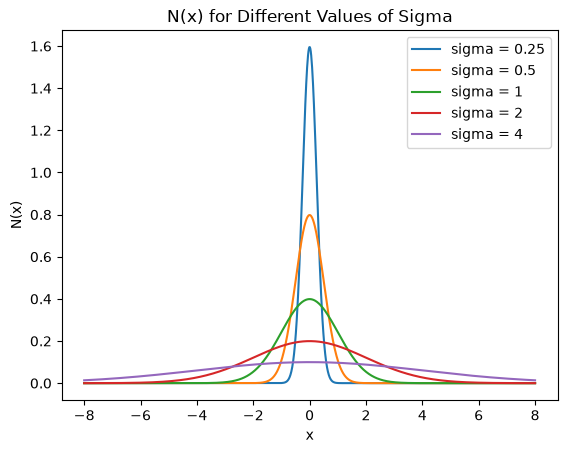

In [5]:
# import numpy for math
import numpy as np
# matplotlib for making graph
import matplotlib.pyplot as plt


#function for the equation given above
def normal_equation(x, sigma):
    """Calculates N(x) using x and sigma."""
    
    # first part of the equation
    front = 1 / (sigma * np.sqrt(2 * np.pi))
    
    #exponent separately because it was long
    exponent = -(x**2) / (2 * sigma**2)
    
    # parts together for whole equation
    N = front * np.exp(exponent)
    
    # have to return N to get answer
    return N

# I used 1000 points just to makes the lines on the graph look smooth
x = np.linspace(-8, 8, 1000) # make x values going from -8 to 8
# values of sigma given
sigma_values = [0.25, 0.5, 1, 2, 4]


for sigma in sigma_values: # loop through each 
    
    # use the function to get N with sigma
    y = normal_equation(x, sigma)
    
    # plot and lable sigma
    plt.plot(x, y, label=f"sigma = {sigma}")

# label whole graph
plt.xlabel("x")
plt.ylabel("N(x)")
plt.title("N(x) for Different Values of Sigma")

# legend added to knwo which sigma
plt.legend()

#graph show
plt.show()